In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib import rcParams

import seaborn as sns

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,confusion_matrix,classification_report,roc_auc_score,roc_curve)
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (Input,Dense,Dropout)

from tensorflow.keras.optimizers import Adam

In [2]:
dataset_path = "UNSW-NB15_1.csv"
df = pd.read_csv(dataset_path, header = None,low_memory=False)

In [3]:
columns = [
    'srcip','sport','dstip','dsport','proto','state',
    'dur','sbytes','dbytes','sttl','dttl','sloss','dloss',
    'service','Sload','Dload','Spkts','Dpkts',
    'swin','dwin','stcpb','dtcpb','smeansz','dmeansz',
    'trans_depth','res_bdy_len','Sjit','Djit',
    'Stime','Ltime','Sintpkt','Dintpkt',
    'tcprtt','synack','ackdat','is_sm_ips_ports',
    'ct_state_ttl','ct_flw_http_mthd','is_ftp_login',
    'ct_ftp_cmd','ct_srv_src','ct_srv_dst',
    'ct_dst_ltm','ct_src_ltm',
    'ct_src_dport_ltm','ct_dst_sport_ltm',
    'ct_dst_src_ltm','attack_cat','label'
]
df.columns = columns

In [4]:
df.describe()

,dur,sbytes,dbytes,sttl,dttl,sloss,dloss,Sload,Dload,Spkts,...,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm,label
count,700001.000000,7.000010e+05,7.000010e+05,700001.000000,700001.000000,700001.000000,700001.000000,7.000010e+05,7.000010e+05,700001.000000,...,700001.000000,700001.000000,700001.000000,700001.000000,700001.000000,700001.000000,700001.000000,700001.000000,700001.000000,700001.000000
mean,0.863391,5.009637e+03,4.833038e+04,38.513848,31.980783,6.330444,21.326271,6.024271e+06,3.011023e+06,41.746643,...,0.019623,0.031116,6.380239,6.034169,4.153233,4.668593,1.685498,1.401911,2.188105,0.031736
std,25.935765,4.489868e+04,1.860516e+05,39.996956,30.450757,18.855979,64.733376,5.181492e+07,4.499952e+06,80.198729,...,0.138700,0.278212,5.075147,4.635608,3.740439,4.189667,1.871052,1.426013,2.211199,0.175296
min,0.000000,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000e+00,0.000000,...,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000
25%,0.003931,4.240000e+02,3.040000e+02,31.000000,29.000000,0.000000,0.000000,7.885915e+04,7.640437e+04,4.000000,...,0.000000,0.000000,2.000000,2.000000,2.000000,2.000000,1.000000,1.000000,1.000000,0.000000
50%,0.027594,2.024000e+03,3.380000e+03,31.000000,29.000000,4.000000,5.000000,5.362718e+05,6.686759e+05,16.000000,...,0.000000,0.000000,5.000000,5.000000,3.000000,4.000000,1.000000,1.000000,1.000000,0.000000
75%,0.346518,3.806000e+03,2.243200e+04,31.000000,29.000000,7.000000,16.000000,1.078489e+06,3.856223e+06,52.000000,...,0.000000,0.000000,9.000000,8.000000,5.000000,6.000000,2.000000,1.000000,3.000000,0.000000
max,8786.637695,1.367739e+07,1.465542e+07,255.000000,254.000000,5096.000000,5483.000000,5.268000e+09,1.287619e+08,10200.000000,...,1.000000,8.000000,44.000000,42.000000,42.000000,50.000000,36.000000,34.000000,38.000000,1.000000


In [5]:
missing_values = df.isnull().sum()

missing_values[missing_values > 0]

attack_cat    677786
dtype: int64

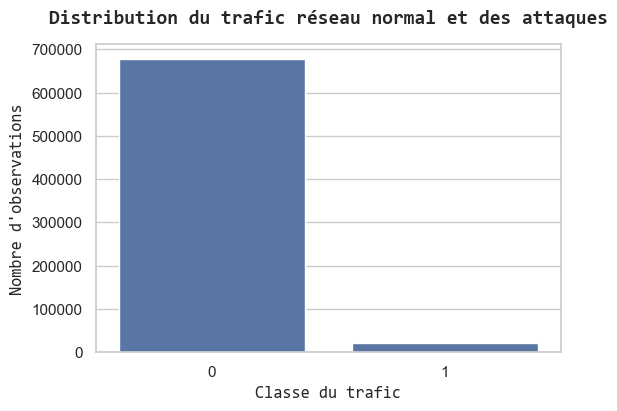

In [6]:
# Configuration de la police Consolas
rcParams['font.family'] = 'Consolas'

# Style graphique
sns.set_theme(style="whitegrid")

plt.figure(figsize=(6,4))

sns.countplot(
    x="label",
    data=df
)


# Titre
plt.title(
    "Distribution du trafic réseau normal et des attaques",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)

plt.xlabel(
    "Classe du trafic",
    fontsize=12,
    fontfamily="Consolas"
)
plt.ylabel(
    "Nombre d'observations",
    fontsize=12,
    fontfamily="Consolas"
)
plt.savefig(
    "distribution_trafic_unsw_nb15.png",
    format="png",
    bbox_inches="tight"
)
plt.show()

In [7]:
# Séparation des variables

X = df.drop(columns=[ "label","attack_cat" ],errors="ignore")
y = df["label"]
print("Variables utilisées :", X.shape)
print("Labels :", y.shape)

Variables utilisées : (700001, 47)
Labels : (700001,)


In [9]:
# Identification des variables catégorielles

categorical_features = X.select_dtypes(
    include=['object']
).columns


print("Variables catégorielles :")
print(categorical_features)

Variables catégorielles :
Index(['srcip', 'sport', 'dstip', 'dsport', 'proto', 'state', 'service'], dtype='object')


In [10]:
# Encodage LabelEncoder

encoder = LabelEncoder()

for col in categorical_features:
    
    X[col] = encoder.fit_transform( X[col].astype(str))

In [15]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)


X_scaled = pd.DataFrame(X_scaled,columns=X.columns)
X_scaled.head()

,srcip,sport,dstip,dsport,proto,state,dur,sbytes,dbytes,sttl,...,ct_flw_http_mthd,is_ftp_login,ct_ftp_cmd,ct_srv_src,ct_srv_dst,ct_dst_ltm,ct_src_ltm,ct_src_dport_ltm,ct_dst_sport_ltm,ct_dst_src_ltm
0,-0.872119,0.226933,-0.382414,0.330437,0.475296,-1.602117,-0.033249,-0.108637,-0.258887,-0.187861,...,-0.201221,-0.141476,-0.111842,-0.666038,0.208351,-0.843012,-0.398264,-0.366370,-0.281843,-0.537313
1,-0.872119,-0.757953,-0.111096,-0.936955,0.475296,-1.602117,-0.031896,-0.099817,-0.258135,-0.187861,...,-0.201221,-0.141476,-0.111842,-0.863077,-0.438814,-0.575663,-0.398264,-0.366370,-0.281843,-0.085070
2,0.524530,0.707514,-0.291975,0.330437,0.475296,-1.602117,-0.033246,-0.108325,-0.258812,-0.187861,...,-0.201221,-0.141476,-0.111842,1.107311,0.424072,-0.843012,-0.636947,0.168089,-0.281843,-0.537313
3,0.291755,-0.610833,-0.472853,0.330437,0.475296,-1.602117,-0.033243,-0.108637,-0.258887,-0.187861,...,-0.201221,-0.141476,-0.111842,-0.074922,0.639794,-0.843012,-0.875630,-0.366370,-0.281843,-0.537313
4,-0.173795,0.280219,1.878568,0.330437,0.475296,-1.602117,-0.033245,-0.108325,-0.258812,-0.187861,...,-0.201221,-0.141476,-0.111842,0.122117,0.639794,-0.843012,-0.875630,-0.366370,-0.281843,-0.537313


In [16]:
# Données normales uniquement

X_normal = X_scaled[y == 0]

X_attack = X_scaled[y == 1]


print("Trafic normal :",X_normal.shape)

print("Attaques :",X_attack.shape)

Trafic normal : (677786, 47)
Attaques : (22215, 47)


In [17]:
X_train, X_val = train_test_split(X_normal, test_size=0.2, random_state=42)

print(X_train.shape)

print(X_val.shape)

(542228, 47)
(135558, 47)


$\text{Construction du modèle Autoencodeur Dense TensorFlow/Keras}$

In [18]:
# ===================================
# Dimension des données d'entrée
# ===================================

input_dim = X_train.shape[1]

print("Nombre de variables utilisées :",input_dim)

Nombre de variables utilisées : 47


In [19]:
# ===================================
# Construction Autoencodeur Dense
# ===================================


input_layer = Input(shape=(input_dim,))


# Encodeur
encoded = Dense(32,activation="relu")(input_layer)

# Bottleneck
encoded = Dense(16,activation="relu",name="bottleneck")(encoded)


# Décodeur
decoded = Dense(32,activation="relu")(encoded)


# Reconstruction finale
output_layer = Dense(input_dim,activation="linear")(decoded)

autoencoder = Model(inputs=input_layer,outputs=output_layer)

autoencoder.summary()


Model: "model"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_1 (InputLayer)        [(None, 47)]              0         
                                                                 
 dense (Dense)               (None, 32)                1536      
                                                                 
 bottleneck (Dense)          (None, 16)                528       
                                                                 
 dense_1 (Dense)             (None, 32)                544       
                                                                 
 dense_2 (Dense)             (None, 47)                1551      
                                                                 
Total params: 4159 (16.25 KB)
Trainable params: 4159 (16.25 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [20]:
# ===================================
# Compilation du modèle
# ===================================


autoencoder.compile(optimizer=Adam(learning_rate=0.001),loss="mse")

In [21]:
# ===================================
# Entraînement
# ===================================

history = autoencoder.fit( X_train, X_train, epochs=50, batch_size=256,validation_data=(X_val,X_val),shuffle=True)

Epoch 1/50

2119/2119 [==============================] - 11s 4ms/step - loss: 0.2305 - val_loss: 0.0969
Epoch 2/50
2119/2119 [==============================] - 8s 4ms/step - loss: 0.1062 - val_loss: 0.0712
Epoch 3/50
2119/2119 [==============================] - 8s 4ms/step - loss: 0.0869 - val_loss: 0.0626
Epoch 4/50
2119/2119 [==============================] - 8s 4ms/step - loss: 0.0738 - val_loss: 0.0601
Epoch 5/50
2119/2119 [==============================] - 8s 4ms/step - loss: 0.0636 - val_loss: 0.0539
Epoch 6/50
2119/2119 [==============================] - 6s 3ms/step - loss: 0.0552 - val_loss: 0.0481
Epoch 7/50
2119/2119 [==============================] - 8s 4ms/step - loss: 0.0507 - val_loss: 0.0445
Epoch 8/50
2119/2119 [==============================] - 8s 4ms/step - loss: 0.0490 - val_loss: 0.0439
Epoch 9/50
2119/2119 [==============================] - 7s 4ms/step - loss: 0.0461 - val_loss: 0.0413
Epoch 10/50
2119/2119 [==============================] - 6s 3ms/step - loss: 0.0

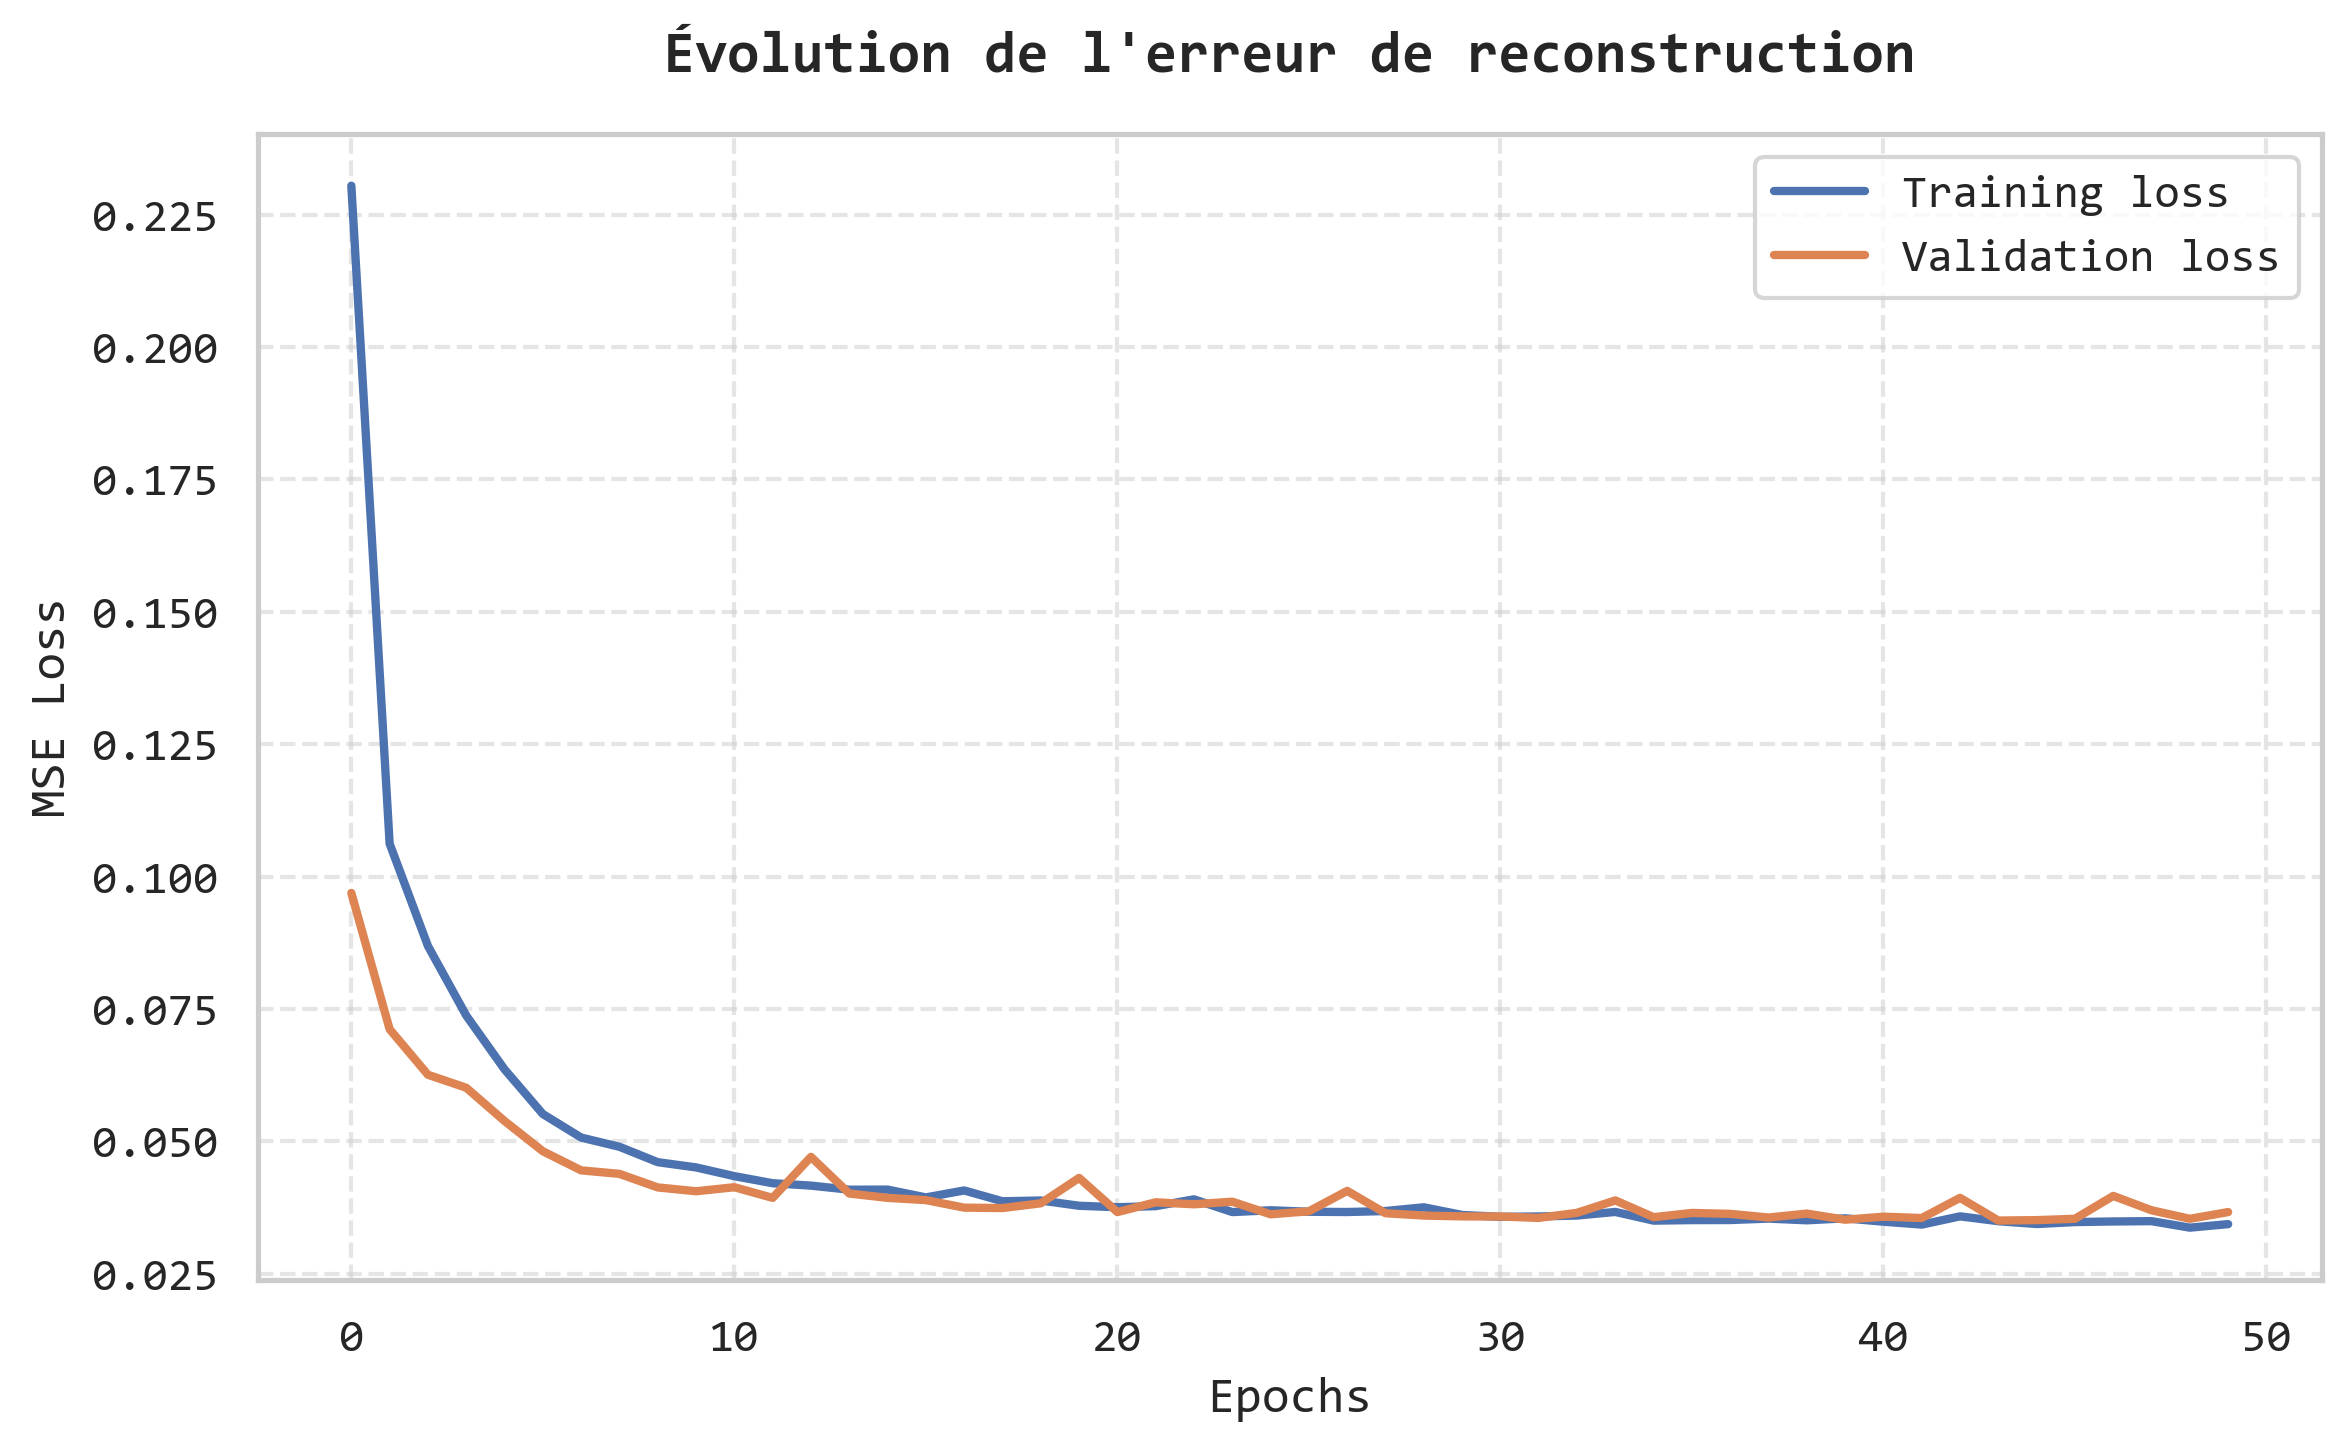

In [22]:
import matplotlib.pyplot as plt
from matplotlib import rcParams

# Configuration globale de la police
rcParams['font.family'] = 'Consolas'

plt.figure(
    figsize=(8,5),
    dpi=300
)

# Courbes
plt.plot(
    history.history["loss"],
    label="Training loss",
    linewidth=2
)

plt.plot(
    history.history["val_loss"],
    label="Validation loss",
    linewidth=2
)

# Labels axes
plt.xlabel(
    "Epochs",
    fontsize=12,
    fontfamily="Consolas"
)

plt.ylabel(
    "MSE Loss",
    fontsize=12,
    fontfamily="Consolas"
)

# Titre
plt.title(
    "Évolution de l'erreur de reconstruction",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)

# Légende
plt.legend(
    fontsize=11,
    prop={
        "family": "Consolas",
        "size": 11
    }
)

# Grille
plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

# Police des graduations
plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.tight_layout()

# Export pour LaTeX
plt.savefig(
    "courbe_loss_autoencoder.png",
    format="png",
    bbox_inches="tight"
)

plt.show()

In [23]:
# ===================================
# Sauvegarde du modèle
# ===================================


autoencoder.save(
    "autoencoder_UNSW_NB15.h5"
)


print(
    "Modèle sauvegardé"
)

Modèle sauvegardé


C:\Users\Taka\anaconda3\envs\tensorflow\lib\site-packages\keras\src\engine\training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


In [24]:
# ===================================
# Reconstruction trafic normal validation
# ===================================


X_val_pred = autoencoder.predict(
    X_val
)


mse_normal = np.mean(
    np.power(
        X_val - X_val_pred,
        2
    ),
    axis=1
)


mse_normal[:10]

4237/4237 [==============================] - 12s 3ms/step


508163    0.008405
521594    0.013705
225406    0.011744
511910    0.005361
480639    0.025605
233916    0.040351
596944    0.008886
343766    0.001217
232093    0.003968
113045    0.014566
dtype: float64

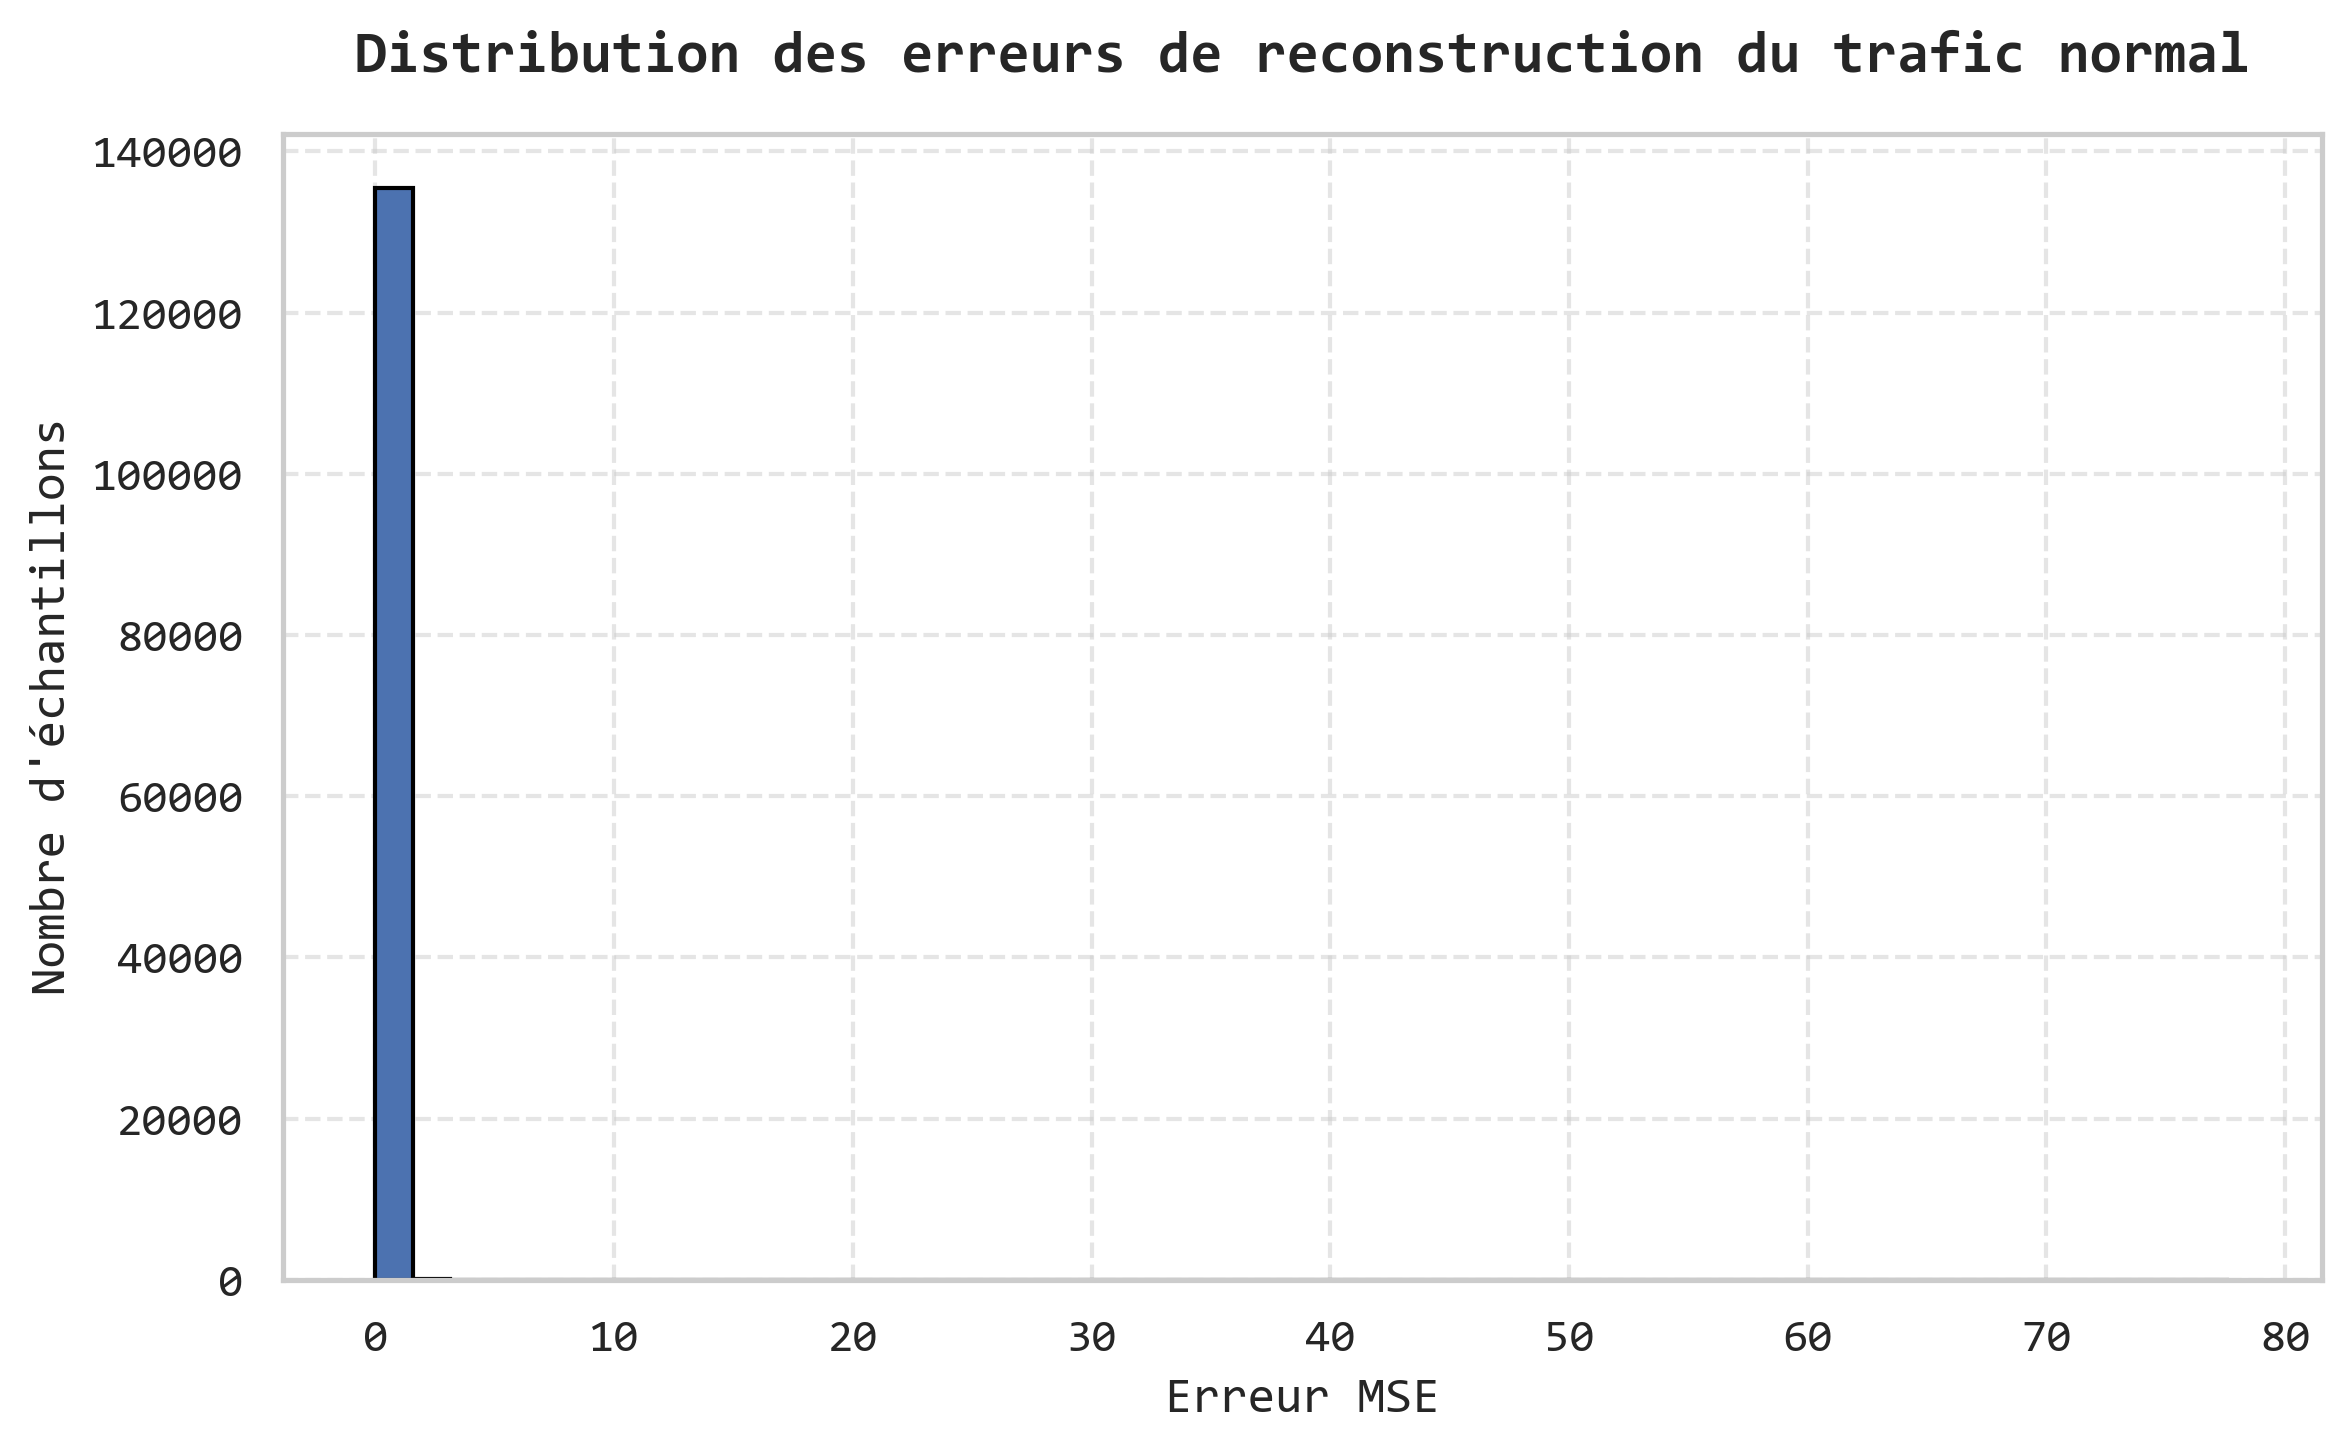

In [25]:
# Police globale
rcParams['font.family'] = 'Consolas'

plt.figure(
    figsize=(8,5),
    dpi=300
)

# Histogramme
plt.hist(
    mse_normal,
    bins=50,
    edgecolor="black"
)

# Labels axes
plt.xlabel(
    "Erreur MSE",
    fontsize=12,
    fontfamily="Consolas"
)

plt.ylabel(
    "Nombre d'échantillons",
    fontsize=12,
    fontfamily="Consolas"
)

# Titre
plt.title(
    "Distribution des erreurs de reconstruction du trafic normal",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)

# Grille
plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)

# Police des graduations
plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.tight_layout()

# Export LaTeX
plt.savefig(
    "distribution_erreur_mse_normal.png",
    format="png",
    bbox_inches="tight"
)

plt.show()

In [26]:
# ===================================
# Calcul du seuil statistique
# ===================================


mean_error = np.mean(
    mse_normal
)


std_error = np.std(
    mse_normal
)


threshold_stat = (
    mean_error 
    + 
    3 * std_error
)


print(
    "Moyenne erreur :",
    mean_error
)


print(
    "Ecart-type :",
    std_error
)


print(
    "Seuil statistique :",
    threshold_stat
)

Moyenne erreur : 0.03665778300863585
Ecart-type : 0.5809627441495837
Seuil statistique : 1.779546015457387


In [27]:
# ===================================
# Seuil percentile 95%
# ===================================


threshold_percentile = np.percentile(
    mse_normal,
    95
)


print(
    "Seuil percentile 95% :",
    threshold_percentile
)

Seuil percentile 95% : 0.08058876482053022


In [28]:
# ===================================
# Ensemble de test complet
# ===================================


X_test = X_scaled


y_test = y.values



print(
    X_test.shape
)


print(
    y_test.shape
)

(700001, 47)
(700001,)


In [29]:
# ===================================
# Reconstruction test
# ===================================


X_test_pred = autoencoder.predict(
    X_test
)


print(
    X_test_pred.shape
)

21876/21876 [==============================] - 50s 2ms/step
(700001, 47)


In [31]:
# ===================================
# Erreur reconstruction test
# ===================================


mse_test = np.mean(
    np.power(
        X_test - X_test_pred,
        2
    ),
    axis=1
)


mse_test[:5]

0    0.013374
1    0.018324
2    0.017917
3    0.013737
4    0.013254
dtype: float64

In [32]:
# ===================================
# Classification anomalie
# ===================================


threshold = threshold_percentile


y_pred = (
    mse_test > threshold
).astype(int)



print(
    y_pred[:30]
)

0     0
1     0
2     0
3     0
4     0
5     0
6     0
7     1
8     0
9     0
10    1
11    1
12    1
13    0
14    0
15    0
16    0
17    0
18    0
19    0
20    1
21    1
22    1
23    0
24    0
25    0
26    0
27    0
28    0
29    0
dtype: int32


In [33]:
accuracy = accuracy_score(
    y_test,
    y_pred
)


print(
    "Accuracy :",
    accuracy
)

Accuracy : 0.9512757838917373


In [34]:
precision = precision_score(
    y_test,
    y_pred
)


recall = recall_score(
    y_test,
    y_pred
)


f1 = f1_score(
    y_test,
    y_pred
)


print(
    "Precision :",
    precision
)


print(
    "Recall :",
    recall
)


print(
    "F1-score :",
    f1
)

Precision : 0.39442846489826355
Recall : 1.0
F1-score : 0.5657206157607243


In [35]:
print(
    classification_report(
        y_test,
        y_pred
    )
)

              precision    recall  f1-score   support

           0       1.00      0.95      0.97    677786
           1       0.39      1.00      0.57     22215

    accuracy                           0.95    700001
   macro avg       0.70      0.97      0.77    700001
weighted avg       0.98      0.95      0.96    700001



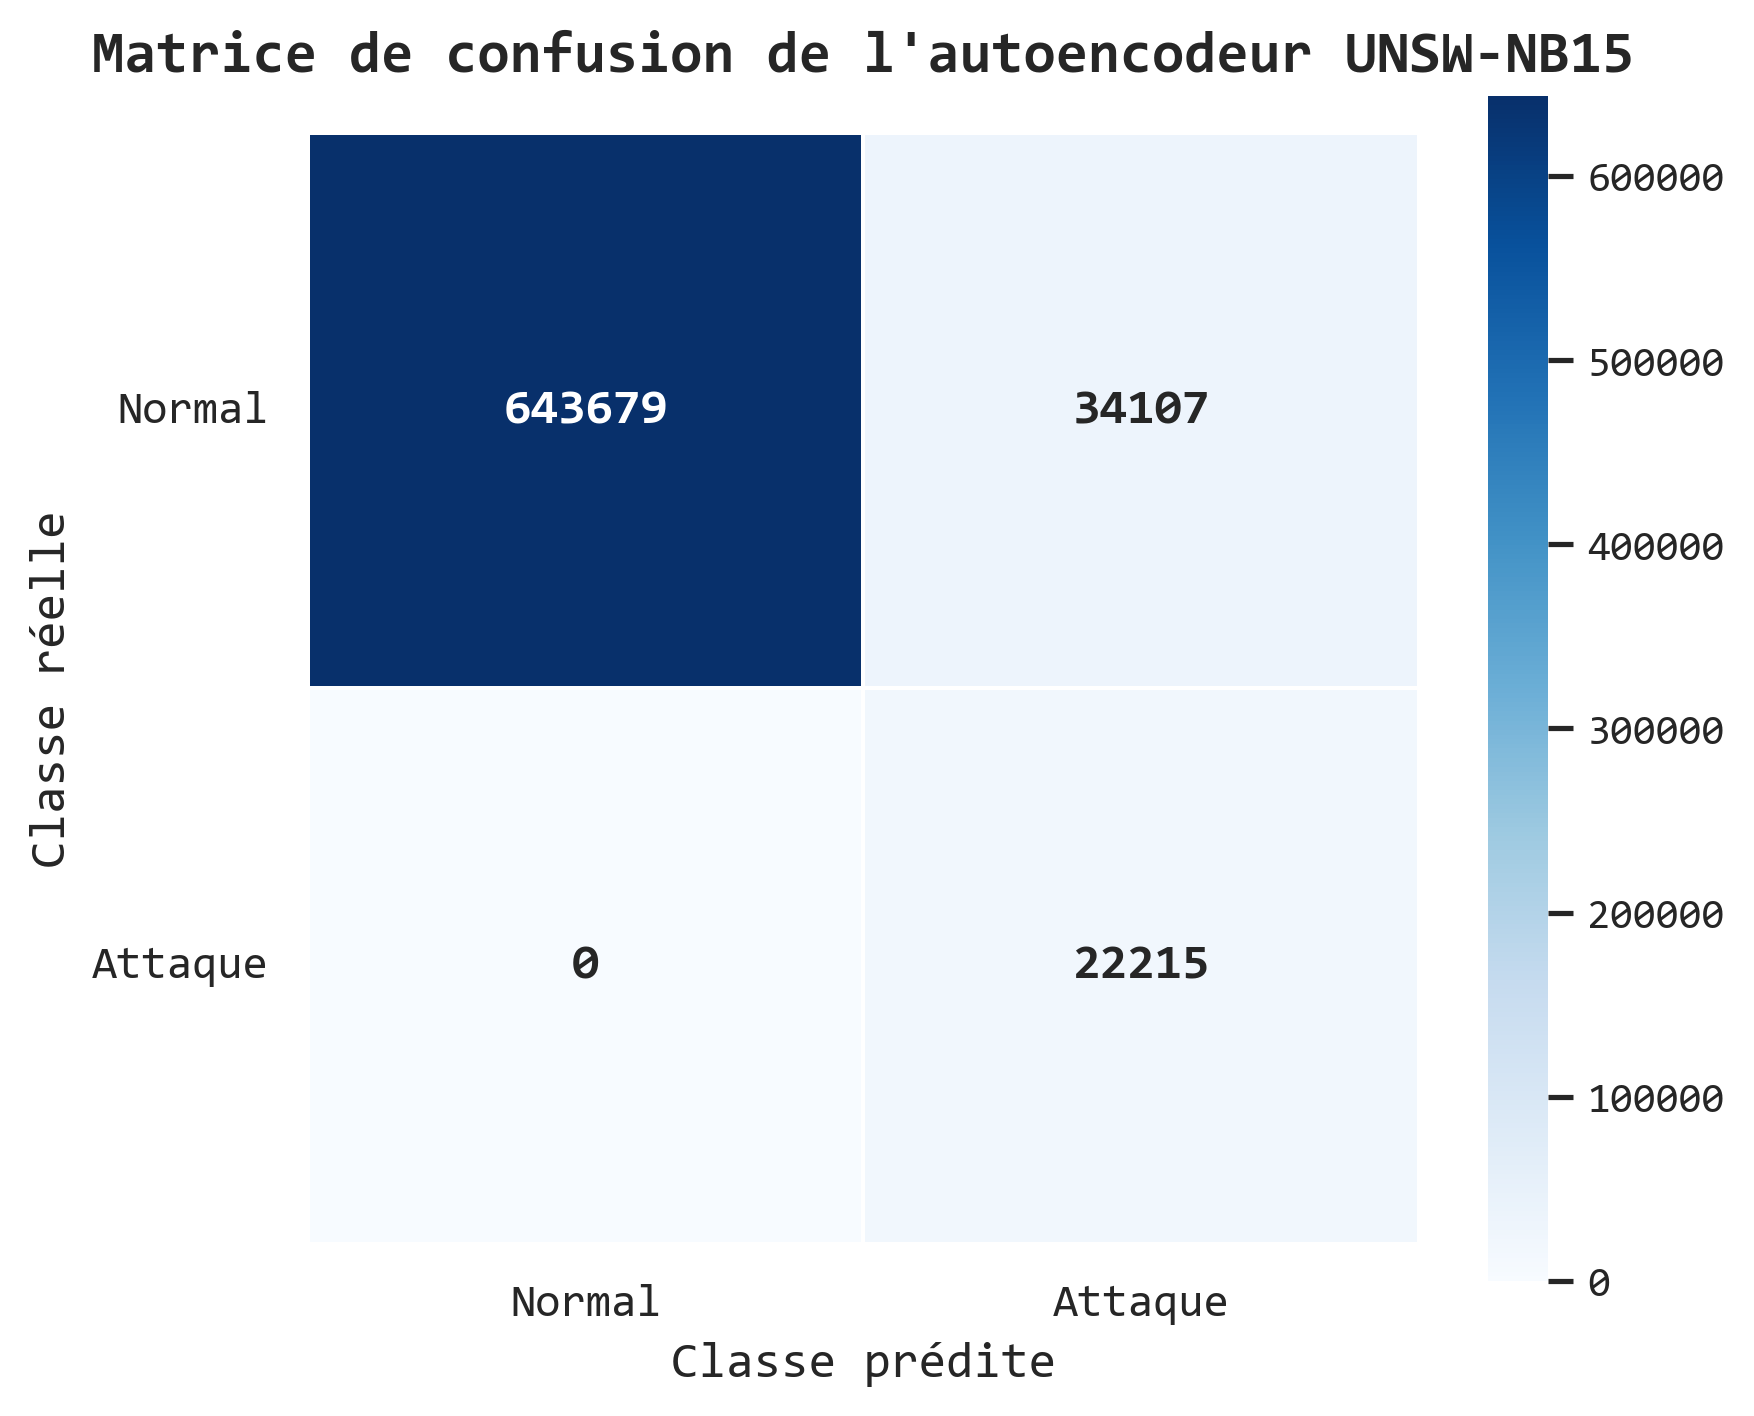

In [36]:
from sklearn.metrics import confusion_matrix
from matplotlib import rcParams

# Police globale
rcParams['font.family'] = 'Consolas'


# Calcul de la matrice
cm = confusion_matrix(
    y_test,
    y_pred
)


plt.figure(
    figsize=(6,5),
    dpi=300
)


ax = sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5,
    square=True,
    cbar=True,
    annot_kws={
        "fontsize":12,
        "fontfamily":"Consolas",
        "fontweight":"bold"
    }
)


# Labels des axes
plt.xlabel(
    "Classe prédite",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Classe réelle",
    fontsize=12,
    fontfamily="Consolas"
)


# Titre
plt.title(
    "Matrice de confusion de l'autoencodeur UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)


# Noms des classes
ax.set_xticklabels(
    ["Normal", "Attaque"],
    fontsize=11,
    fontfamily="Consolas"
)

ax.set_yticklabels(
    ["Normal", "Attaque"],
    fontsize=11,
    fontfamily="Consolas",
    rotation=0
)


# Police de la barre de couleur
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=10)

for label in cbar.ax.get_yticklabels():
    label.set_fontname("Consolas")


plt.tight_layout()


# Export LaTeX
plt.savefig(
    "matrice_confusion_autoencoder_unsw_nb15.png",
    format="png",
    bbox_inches="tight"
)


plt.show()

In [37]:
auc = roc_auc_score(
    y_test,
    mse_test
)


print(
    "ROC-AUC :",
    auc
)

ROC-AUC : 0.9925524399340164


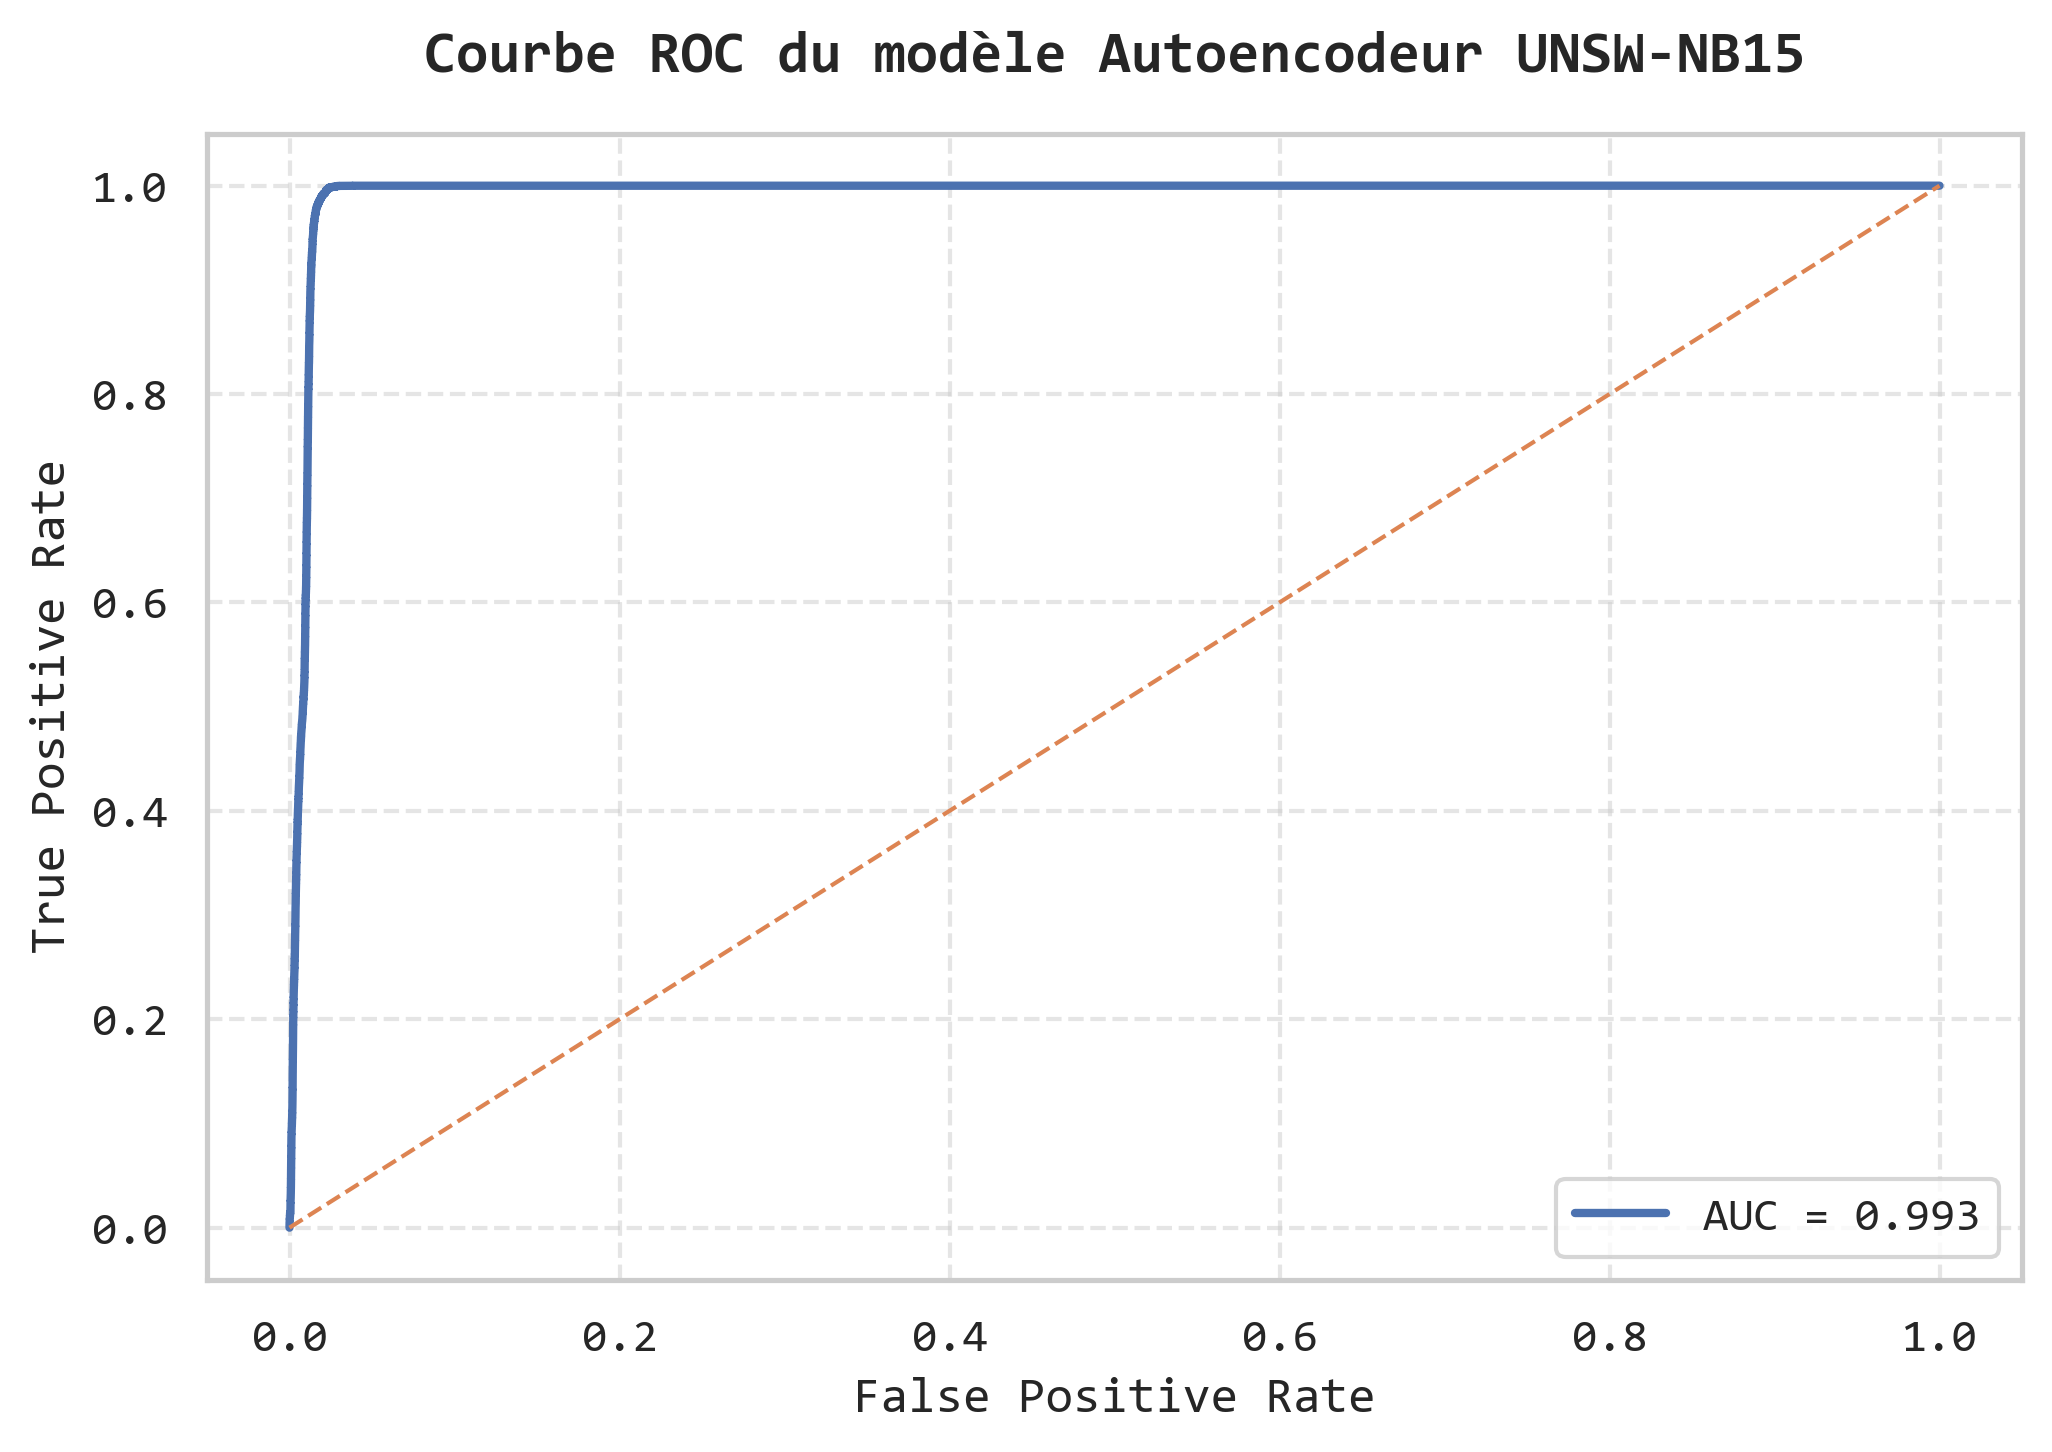

In [38]:
from sklearn.metrics import roc_curve, auc
from matplotlib import rcParams

# Police globale
rcParams['font.family'] = 'Consolas'


# Calcul ROC
fpr, tpr, thresholds = roc_curve(
    y_test,
    mse_test
)

# Calcul AUC
roc_auc = auc(
    fpr,
    tpr
)


plt.figure(
    figsize=(7,5),
    dpi=300
)


# Courbe ROC
plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc:.3f}"
)


# Ligne aléatoire
plt.plot(
    [0,1],
    [0,1],
    linestyle="--",
    linewidth=1
)


# Axes
plt.xlabel(
    "False Positive Rate",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "True Positive Rate",
    fontsize=12,
    fontfamily="Consolas"
)


# Titre
plt.title(
    "Courbe ROC du modèle Autoencodeur UNSW-NB15",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)


# Légende
plt.legend(
    fontsize=11,
    prop={
        "family":"Consolas",
        "size":11
    }
)


# Grille
plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)


# Police graduations
plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)


plt.tight_layout()


# Export LaTeX
plt.savefig(
    "courbe_roc_autoencoder_unsw_nb15.png",
    format="png",
    bbox_inches="tight"
)


plt.show()

In [39]:
# ===================================
# Fonction comparaison des seuils
# ===================================


def evaluate_threshold(
    threshold,
    mse_values,
    y_true
):
    
    y_pred = (
        mse_values > threshold
    ).astype(int)


    results = {
        "Threshold": threshold,
        "Accuracy": accuracy_score(
            y_true,
            y_pred
        ),
        "Precision": precision_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "Recall": recall_score(
            y_true,
            y_pred,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_true,
            y_pred,
            zero_division=0
        )
    }


    return results

In [40]:
# ===================================
# Comparaison seuils
# ===================================


results_threshold = []


# seuil statistique

results_threshold.append(
    evaluate_threshold(
        threshold_stat,
        mse_test,
        y_test
    )
)



# seuil percentile

results_threshold.append(
    evaluate_threshold(
        threshold_percentile,
        mse_test,
        y_test
    )
)



threshold_results = pd.DataFrame(
    results_threshold
)


threshold_results

,Threshold,Accuracy,Precision,Recall,F1-score
0,1.779546,0.968624,0.591837,0.036552,0.068851
1,0.080589,0.951276,0.394428,1.000000,0.565721


In [41]:
# ===================================
# Recherche seuil optimal
# ===================================


thresholds = np.linspace(
    mse_test.min(),
    mse_test.max(),
    200
)


best_threshold = None
best_f1 = 0



for t in thresholds:

    y_temp = (
        mse_test > t
    ).astype(int)


    score = f1_score(
        y_test,
        y_temp,
        zero_division=0
    )


    if score > best_f1:
        
        best_f1 = score
        best_threshold = t



print(
    "Meilleur seuil :",
    best_threshold
)


print(
    "Meilleur F1-score :",
    best_f1
)

Meilleur seuil : 0.0003966939915609713
Meilleur F1-score : 0.06151907672922883


In [42]:
threshold_optimal = best_threshold

In [43]:
# ===================================
# Prédiction seuil optimal
# ===================================


y_pred_optimal = (
    mse_test > threshold_optimal
).astype(int)



print(
    classification_report(
        y_test,
        y_pred_optimal
    )
)

              precision    recall  f1-score   support

           0       1.00      0.00      0.00    677786
           1       0.03      1.00      0.06     22215

    accuracy                           0.03    700001
   macro avg       0.52      0.50      0.03    700001
weighted avg       0.97      0.03      0.00    700001



In [44]:
# ===================================
# Tableau final comparaison
# ===================================


final_results = pd.DataFrame(
    [
        evaluate_threshold(
            threshold_stat,
            mse_test,
            y_test
        ),

        evaluate_threshold(
            threshold_percentile,
            mse_test,
            y_test
        ),

        evaluate_threshold(
            threshold_optimal,
            mse_test,
            y_test
        )
    ]
)


final_results

,Threshold,Accuracy,Precision,Recall,F1-score
0,1.779546,0.968624,0.591837,0.036552,0.068851
1,0.080589,0.951276,0.394428,1.000000,0.565721
2,0.000397,0.031737,0.031736,1.000000,0.061519


In [45]:
attack_categories = df["attack_cat"]
print(attack_categories.value_counts())

attack_cat
Generic           7522
Exploits          5409
 Fuzzers          5051
Reconnaissance    1759
DoS               1167
Backdoors          534
Analysis           526
Shellcode          223
Worms               24
Name: count, dtype: int64


In [46]:
# ===================================
# Analyse par catégorie
# ===================================


analysis_df = pd.DataFrame(
    {
        "attack_cat": attack_categories,
        "true_label": y_test,
        "prediction": y_pred_optimal
    }
)



attack_results = (
    analysis_df
    .groupby("attack_cat")
    .apply(
        lambda x:
        pd.Series(
            {
                "Detection_rate":
                recall_score(
                    x["true_label"],
                    x["prediction"],
                    zero_division=0
                )
            }
        )
    )
)



attack_results

C:\Users\Taka\AppData\Local\Temp\ipykernel_10996\3115241698.py:19: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Detection_rate
attack_cat,
Fuzzers,1.0
Analysis,1.0
Backdoors,1.0
DoS,1.0
Exploits,1.0
Generic,1.0
Reconnaissance,1.0
Shellcode,1.0
Worms,1.0


In [47]:
# ===================================
# Extraction représentation latente
# ===================================


encoder_model = Model(
    inputs=autoencoder.input,
    outputs=autoencoder.get_layer(
        "bottleneck"
    ).output
)


latent_features = encoder_model.predict(
    X_test
)


print(
    latent_features.shape
)

21876/21876 [==============================] - 51s 2ms/step
(700001, 16)


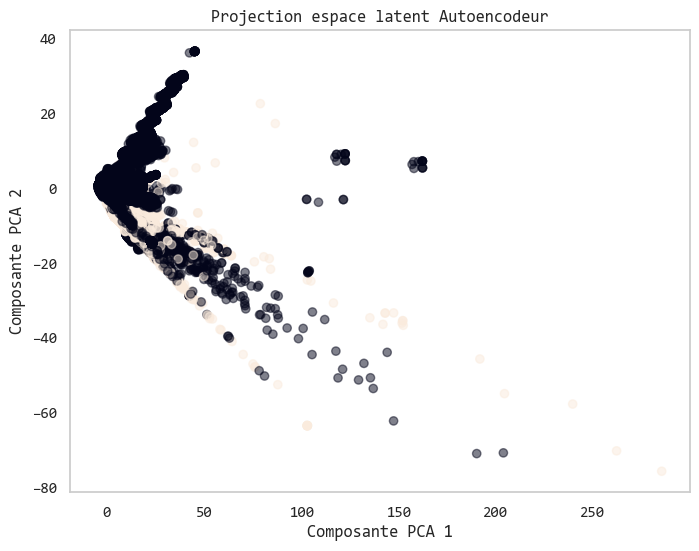

In [48]:
from sklearn.decomposition import PCA



pca = PCA(
    n_components=2
)



latent_2D = pca.fit_transform(
    latent_features
)



plt.figure(
    figsize=(8,6)
)



plt.scatter(
    latent_2D[:,0],
    latent_2D[:,1],
    c=y_test,
    alpha=0.5
)



plt.xlabel(
    "Composante PCA 1"
)


plt.ylabel(
    "Composante PCA 2"
)


plt.title(
    "Projection espace latent Autoencodeur"
)


plt.grid()

plt.show()

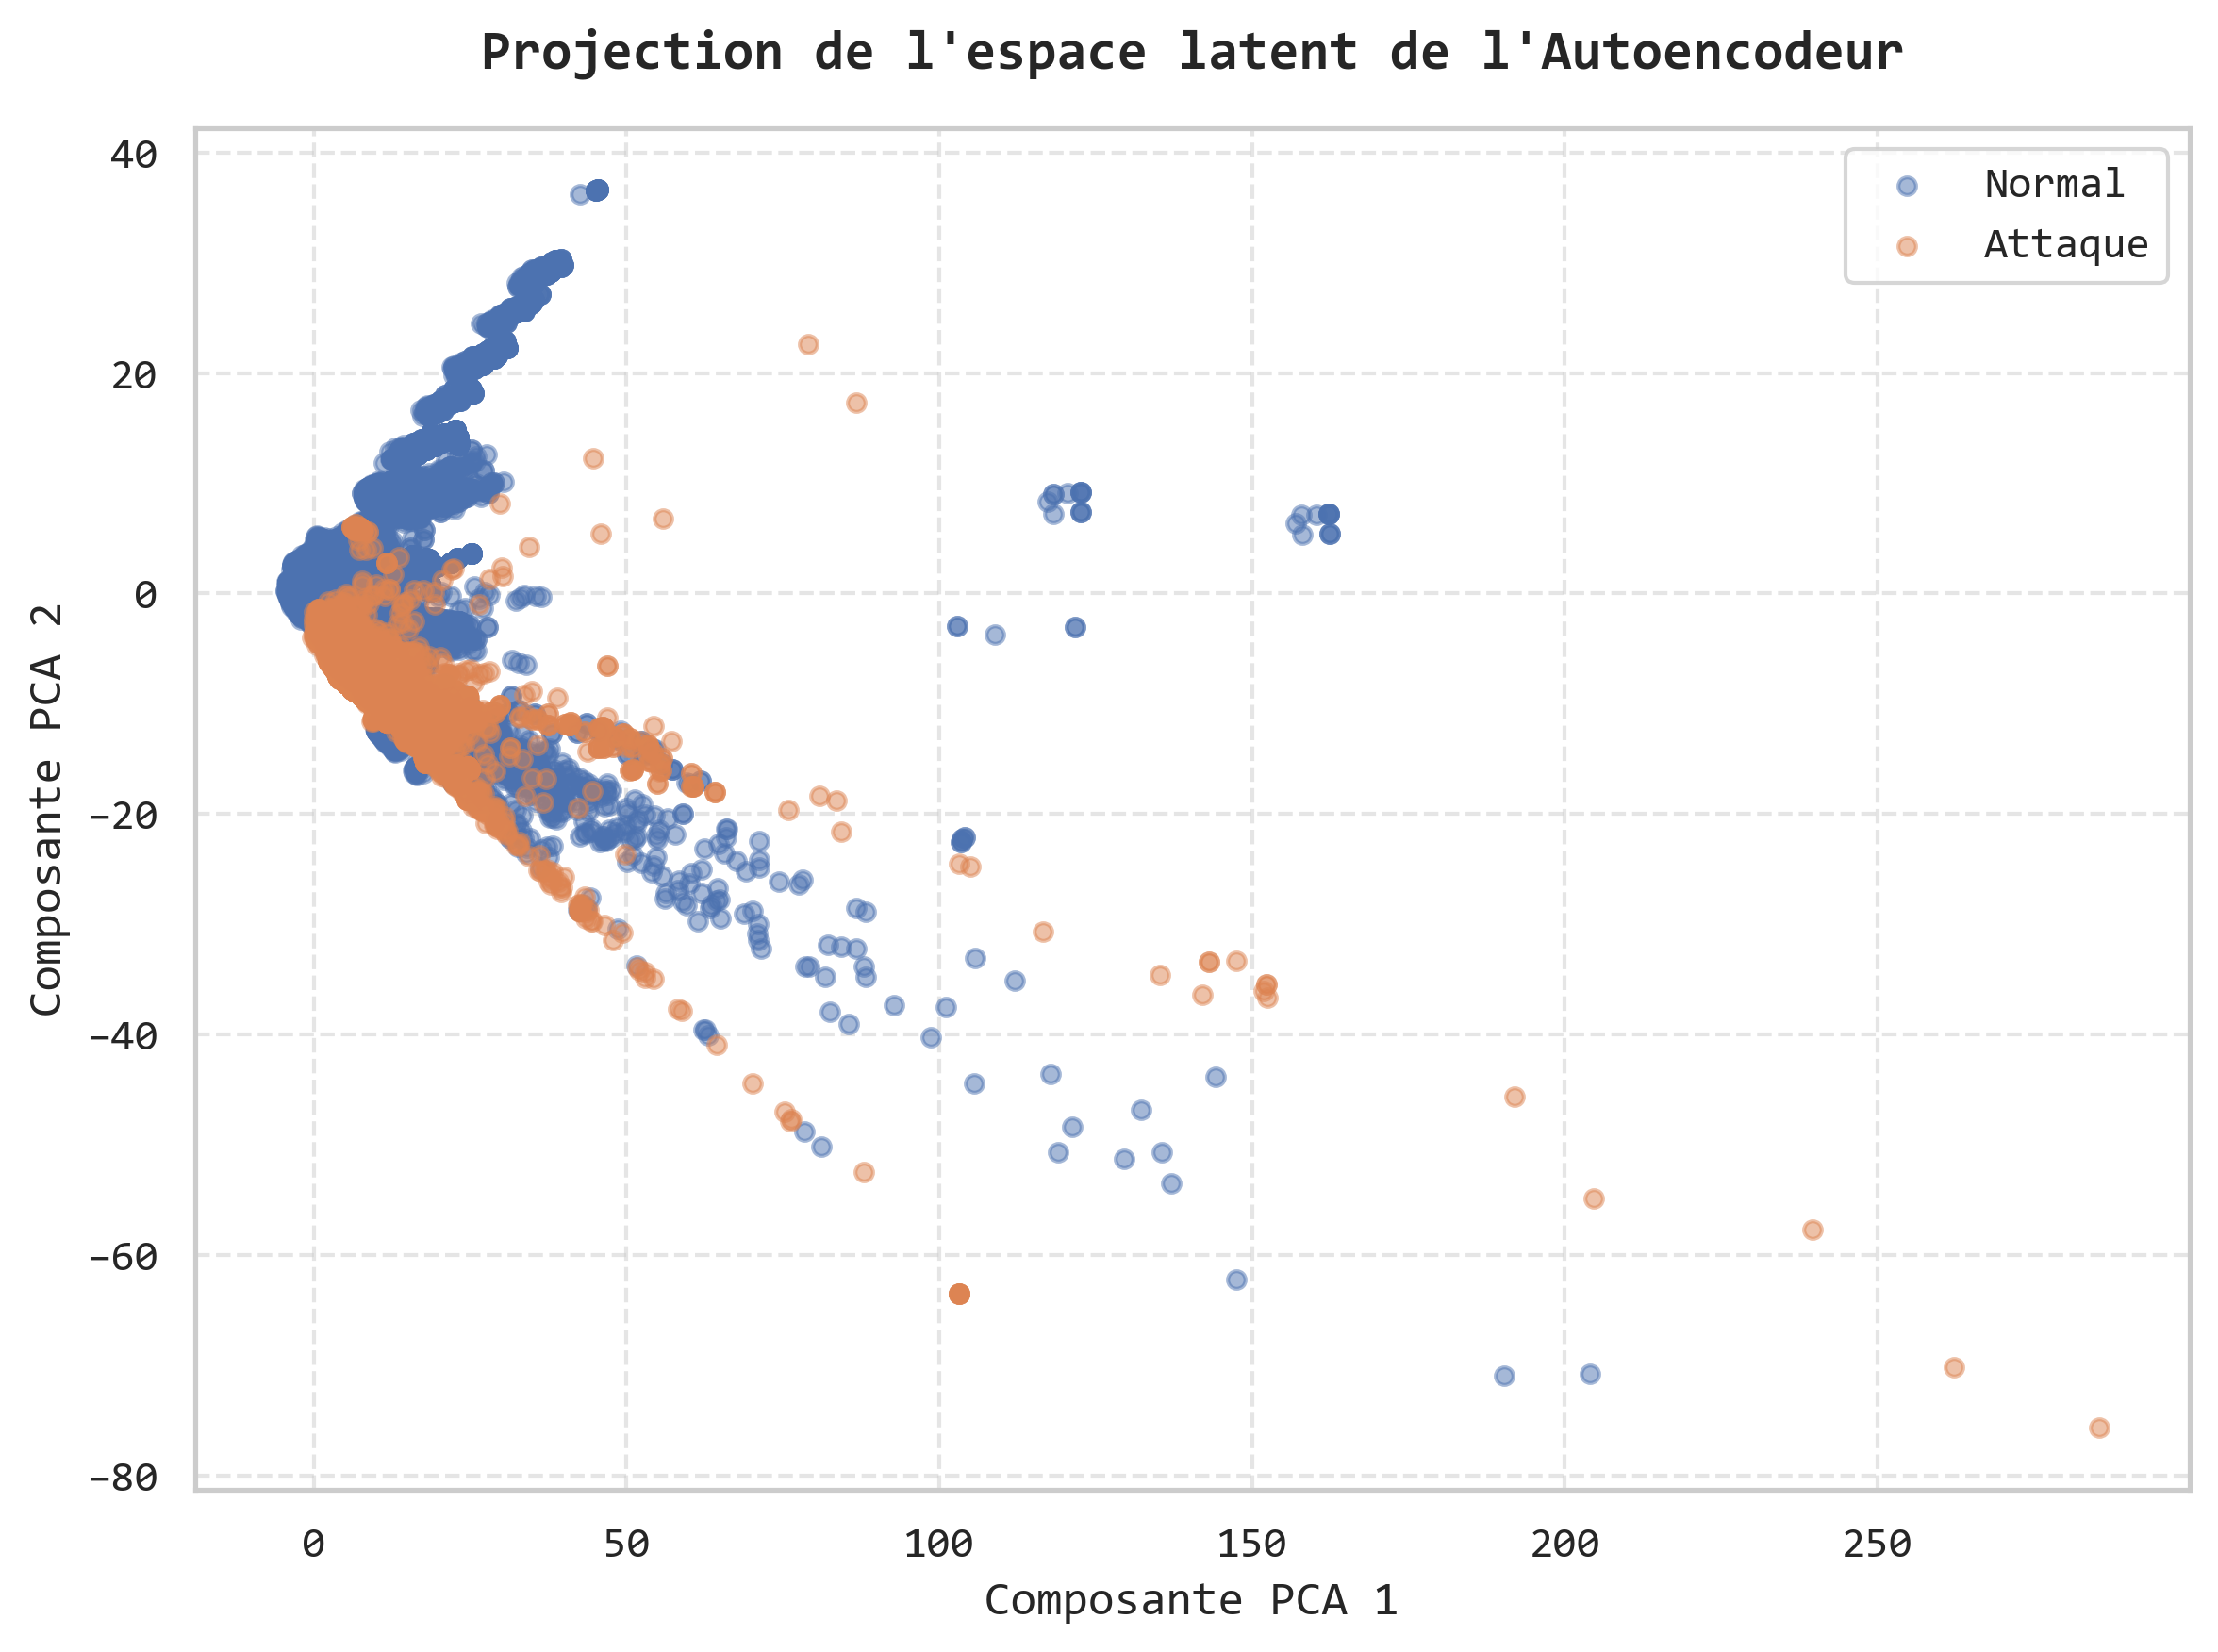

In [49]:
# ===================================
# Projection espace latent Autoencodeur
# PCA 2D
# Police Consolas
# ===================================

from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
from matplotlib import rcParams
import numpy as np


# Police globale
rcParams['font.family'] = 'Consolas'


# Réduction PCA
pca = PCA(
    n_components=2
)


latent_2D = pca.fit_transform(
    latent_features
)


plt.figure(
    figsize=(8,6),
    dpi=300
)


# Séparation des classes
normal = y_test == 0
attaque = y_test == 1


# Classe normale
plt.scatter(
    latent_2D[normal, 0],
    latent_2D[normal, 1],
    label="Normal",
    alpha=0.5,
    s=20
)


# Classe attaque
plt.scatter(
    latent_2D[attaque, 0],
    latent_2D[attaque, 1],
    label="Attaque",
    alpha=0.5,
    s=20
)


# Axes
plt.xlabel(
    "Composante PCA 1",
    fontsize=12,
    fontfamily="Consolas"
)


plt.ylabel(
    "Composante PCA 2",
    fontsize=12,
    fontfamily="Consolas"
)


# Titre
plt.title(
    "Projection de l'espace latent de l'Autoencodeur",
    fontsize=14,
    fontweight="bold",
    fontfamily="Consolas",
    pad=15
)


# Légende
plt.legend(
    fontsize=11,
    prop={
        "family":"Consolas",
        "size":11
    }
)


# Grille
plt.grid(
    True,
    linestyle="--",
    alpha=0.5
)


# Graduations
plt.xticks(
    fontsize=11,
    fontfamily="Consolas"
)

plt.yticks(
    fontsize=11,
    fontfamily="Consolas"
)


plt.tight_layout()


# Export pour LaTeX
plt.savefig(
    "projection_espace_latent_pca_autoencoder.png",
    dpi=300,
    bbox_inches="tight"
)


plt.show()

In [50]:
# ===================================
# Export résultats
# ===================================


results_export = pd.DataFrame(
    {
        "MSE": mse_test,
        "True_Label": y_test,
        "Prediction": y_pred_optimal
    }
)


results_export.to_csv(
    "autoencoder_results_UNSW_NB15.csv",
    index=False
)



final_results.to_csv(
    "threshold_comparison.csv",
    index=False
)



print(
    "Résultats exportés"
)

Résultats exportés
